# **XOR 해결하기**

In [1]:
# GPU 확인
import torch
import numpy as np

In [2]:
print(torch.cuda.device_count())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No CUDA GPU detected")

1
NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [3]:
print(torch.__version__)
print(torch.version.cuda)

2.14.1+cu130
13.0


pyTorch의 tensor들을 활용하여 XOR 문제를 해결해본다.

## **1.순전파 (Forward)**

**Q1. torch.tensor로 XOR의 데이터를 만들어줍니다.**

- 입력 X : XOR의 입력 4가지 조합 [(0,0) (0,1) (1,0) (1,1)]
- 정답 y : 각 입력에 대한 XOR 결과 [0, 1, 1, 0]
- 반드시 실수(float)로 만들어야 한다.
- y_tensor의 shape를 (4,1)로 변환한다.


In [4]:
X = [[0,0],[0,1],[1,0],[1,1]]
y = [0, 1, 1, 0]

In [ ]:
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).view(4,1)

print(X_tensor.shape, y_tensor.shape)

torch.Size([4, 2]) torch.Size([4, 1])


**Q2. MLP 클래스의 parameter를 만들어줍니다.**

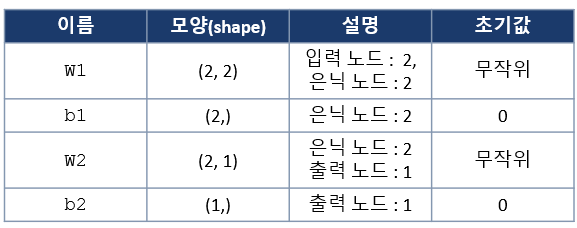

- 무작위 초기화는 torch.randn, 0 초기화는 torch.zeros를 쓴다.
- 가중치 shape은 (들어오는 노드 수, 나가는 노드 수) 순서다.


In [10]:
class MLP:
    def __init__(self):
        self.w1 = torch.randn(2, 2) # input 2 -> output 2
        self.b1 = torch.zeros(2)
        self.w2 = torch.randn(2, 1)
        self.b2 = torch.zeros(1)

**Q3. Sigmoid 함수를 정의한다.**

```
1 / (1 + torch.exp^(-z))
```

In [11]:
def sigmoid(z):
    return 1 / (1 + torch.exp(-z))

**Q4. 순전파를 계산하여 구현한다.**

클래스 내에 forward()라는 메소드로 구현한다.

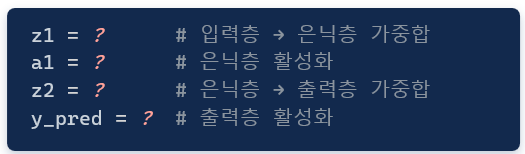

In [40]:
class MLP:
    def __init__(self):
        self.w1 = torch.randn(2, 2) # input 2 -> output 2
        self.b1 = torch.zeros(2)
        self.w2 = torch.randn(2, 1)
        self.b2 = torch.zeros(1)

    def forward(self, X):
        # 첫번째 층 (입력 -> 은닉 + b ==> sigmoid 통과)
        self.z1 = X @ self.w1 + self.b1
        self.a1 = sigmoid(self.z1)

        # 두번째 층 (first layer -> 은닉 + b => sigmoid 통과)
        self.z2 = self.a1 @ self.w2 + self.b2
        self.a2 = sigmoid(self.z2)

        return self.a2


**Q5. Q4에서 구현된 각 단계에서 .shape를 출력하여 아래의 표와 맞는지 확인해보자.**
- 완성된 신경망 모델의 인스턴스를 생성해보고, XOR 데이터를 학습 (forward) 시켜본다.

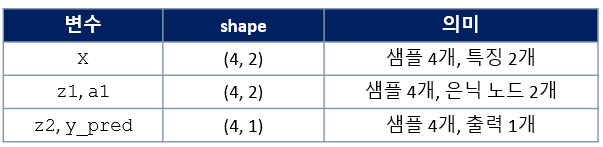

In [41]:
mlp = MLP()
y_pred = mlp.forward(X_tensor)

print(f"X : {X_tensor.shape}")
print(f"z1, a1 : {mlp.z1.shape, mlp.a1.shape}")
print(f"z2 : {mlp.z2.shape}")
print(f"y_pred: {y_pred.shape}")

X : torch.Size([4, 2])
z1, a1 : (torch.Size([4, 2]), torch.Size([4, 2]))
z2 : torch.Size([4, 1])
y_pred: torch.Size([4, 1])


**Q6. 학습된 신경망의 예측 결과를 출력해보자.**

아직은 전혀 맞지 않는 것이 정상이다.

In [43]:
mlp = MLP()
y_pred = mlp.forward(X_tensor)
y_pred

tensor([[0.4045],
        [0.3313],
        [0.4067],
        [0.3329]])

## **2. Loss 함수**

**Q1. MLP 클래스에 BCE (binary cross entropy)를 구하는 bce_loss 함수를 구현한다.**

```
bce_loss = -(y_true*torch.log(y_pred) + (1-y_true)*torch.log(1-y_pred)).mean()
```


In [47]:
class MLP:
    def __init__(self):
        self.w1 = torch.randn(2, 2) # input 2 -> output 2
        self.b1 = torch.zeros(2)
        self.w2 = torch.randn(2, 1)
        self.b2 = torch.zeros(1)

    def forward(self, X):
        # 첫번째 층 (입력 -> 은닉 + b ==> sigmoid 통과)
        self.z1 = X @ self.w1 + self.b1
        self.a1 = sigmoid(self.z1)

        # 두번째 층 (first layer -> 은닉 + b => sigmoid 통과)
        self.z2 = self.a1 @ self.w2 + self.b2
        self.a2 = sigmoid(self.z2)

        return self.a2

    def bce_loss(self, y_true, y_pred):
        return -(y_true * torch.log(y_pred) + (1-y_true)*torch.log(1-y_pred)).mean()

**Q2. forward()를 통해 신경망을 학습시킨 후, loss를 출력해보자.**

In [48]:
mlp = MLP()
y_pred = mlp.forward(X_tensor)
loss = mlp.bce_loss(y_tensor, y_pred)
loss

tensor(0.7053)

## **3. 역전파 (Backpropagation)**

**Q1. backpropagation 함수를 구현한다.**

- 필요한 정보들은 mlp.w2, mlp.a1,mlp.a2를 활용한다.

In [49]:
def backward(mlp, X, y):
    n = X.shape[0]

    # 출력층 -> 은닉층: BCE와 시그모이드를 함께 미분
    dL_dz2 = mlp.a2 - y                 # dL/dz2
    mlp.dw2 = mlp.a1.T @ dL_dz2 / n     # dL/dw2 = a1.T @ dz2
    mlp.db2 = dL_dz2.mean(dim=0)        # dL/db2

    # 은닉층 -> 입력층 (w2와 시그모이드의 미분 a1(1-a1)을 곱함)
    dL_da1 = dL_dz2 @ mlp.w2.T
    dL_dz1 = dL_da1 * mlp.a1 * (1 - mlp.a1)
    mlp.dw1 = X.T @ dL_dz1 / n
    mlp.db1 = dL_dz1.mean(dim=0)

**Q2. 위에서 만든 MLP의 인스턴스를 생성하고, 한 번 forward를 한 후, backward로 역전파를 한다.**

그리고 역전파를 통해 찾은 기울기값들을 출력한다.

In [51]:
mlp = MLP()
y_pred = mlp.forward(X_tensor)
print(mlp.w1)
print(mlp.b1)
print(mlp.w2)
print(mlp.b2)

backward(mlp, X_tensor, y_tensor)

print('----------------')

print(mlp.dw1)
print(mlp.db1)
print(mlp.dw2)
print(mlp.db2)

tensor([[-0.9077,  0.7721],
        [ 0.0875,  0.6701]])
tensor([0., 0.])
tensor([[ 1.0089],
        [-0.5735]])
tensor([0.])
----------------
tensor([[-0.0025,  0.0061],
        [-0.0045,  0.0046]])
tensor([0.0033, 0.0011])
tensor([[ 0.0063],
        [-0.0039]])
tensor([0.0066])


## **4. Gradient Descent**

**Q1. gradient descent를 구현해보자.**

In [55]:
def gradient_descent(mlp, lr):
    mlp.w1 -= mlp.dw1 * lr
    mlp.b1 -= mlp.db1 * lr
    mlp.w2 -= mlp.dw2 * lr
    mlp.b2 -= mlp.db2 * lr

**Q2. learning rate = 1.0, epoch = 1000으로 설정하고, 학습시켜보자.**

- forward() -> loss() -> backward() -> gd() 의 순서를 따라간다.

In [56]:
mlp = MLP()
lr, epochs = 1, 1000

for epoch in range(epochs):
    #1. forward
    y_pred = mlp.forward(X_tensor)
    #2. Loss
    loss = mlp.bce_loss(y_tensor, y_pred)
    #3. Backward
    backward(mlp, X_tensor, y_tensor)
    #4. Gradient Descent
    gradient_descent(mlp, lr)

    if epoch % 100 == 0:
        print(f'epoch = {epoch} : loss = {loss}')

epoch = 0 : loss = 0.7467350959777832
epoch = 100 : loss = 0.6922499537467957
epoch = 200 : loss = 0.6844116449356079
epoch = 300 : loss = 0.6143234968185425
epoch = 400 : loss = 0.41555002331733704
epoch = 500 : loss = 0.14579454064369202
epoch = 600 : loss = 0.0674004852771759
epoch = 700 : loss = 0.04185289144515991
epoch = 800 : loss = 0.0299338661134243
epoch = 900 : loss = 0.023159988224506378


In [57]:
y_pred = mlp.forward(X_tensor)
print(y_tensor)
print(y_pred)

tensor([[0.],
        [1.],
        [1.],
        [0.]])
tensor([[0.0219],
        [0.9830],
        [0.9830],
        [0.0187]])


## **5. torch.autograd**

**Q1. torch.autograd의 기능들을 활용하여 위 코드를 리팩토링해보자.**

1. 모든 weight과 bias에 requires_grad 옵션을 추가한다.
2. sigmoid 함수를 삭제하고 torch.sigmoid로 대체한다.
3. bce_loss 함수의 내용을 삭제하고 torch.nn.functional.binary_cross_entropy로 대체한다.
4. backward()함수를 loss.backward()로 대체한다.
5. gradient descent는 각 weight의 .grad를 활용하여 계산한다.

In [61]:
import torch.nn.functional as F

class MLP:
    def __init__(self):
        self.w1 = torch.randn(2, 2, requires_grad=True)
        self.b1 = torch.zeros(2, requires_grad=True)
        self.w2 = torch.randn(2, 1, requires_grad=True)
        self.b2 = torch.zeros(1, requires_grad=True)

    def forward(self, X):
        # 첫번째 층 (입력 -> 은닉 + b ==> sigmoid 통과)
        self.z1 = X @ self.w1 + self.b1
        self.a1 = torch.sigmoid(self.z1)

        # 두번째 층 (first layer -> 은닉 + b => sigmoid 통과)
        self.z2 = self.a1 @ self.w2 + self.b2
        self.a2 = torch.sigmoid(self.z2)

        return self.a2

    def bce_loss(self, y_pred, y_true):
        return F.binary_cross_entropy(y_pred, y_true)

def gd(mlp, lr):
    with torch.no_grad(): # 파라미터 갱신은 계산 그래프에 기록하지 않음
        for p in (mlp.w1, mlp.b1, mlp.w2, mlp.b2):
            p -= lr * p.grad
            p.grad.zero_() # 기울기는 누적되므로 매번 비움

직접 만든 backward()는 loss.backward()로 바뀌고, 기울기는 각 parameter의 .grad에 저장된다.

주의할 점:
    - torch.no_grad() : requires_grad=True인 텐서를 그대로 제자리 수정하면 에러 발생
    - .grad.zero_() : backward() 는 기울기를 더해 나가므로, 비우지 않으면 이전 기울기가 계속 쌓임

**Q2. MLP 신경망을 생성하고, forward()를 진행하여 결과를 y_pred에 저장한다.**

In [62]:
torch.manual_seed(0)
mlp = MLP()
y_pred = mlp.forward(X_tensor)
print(y_pred)

tensor([[0.2242],
        [0.2683],
        [0.1838],
        [0.2369]], grad_fn=<SigmoidBackward0>)


In [64]:
for epoch in range(1, 1001):
    y_pred = mlp.forward(X_tensor)
    loss = mlp.bce_loss(y_pred, y_tensor)
    loss.backward()
    gd(mlp, 1.0)
    if epoch % 200 == 0:
        print(f"epoch {epoch:4d} | loss {loss.item():.4f}")

y_pred = mlp.forward(X_tensor)
print(f"예측 {y_pred}")
print(f"예측: {(y_pred >= .5).int().flatten().tolist()}")
print(f"정답 {y}")

epoch  200 | loss 0.0193
epoch  400 | loss 0.0159
epoch  600 | loss 0.0135
epoch  800 | loss 0.0117
epoch 1000 | loss 0.0103
예측 tensor([[0.0091],
        [0.9881],
        [0.9880],
        [0.0080]], grad_fn=<SigmoidBackward0>)
예측: [0, 1, 1, 0]
정답 [0, 1, 1, 0]
